<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Train: (300, 8), Val: (100, 8), Test: (100, 8)



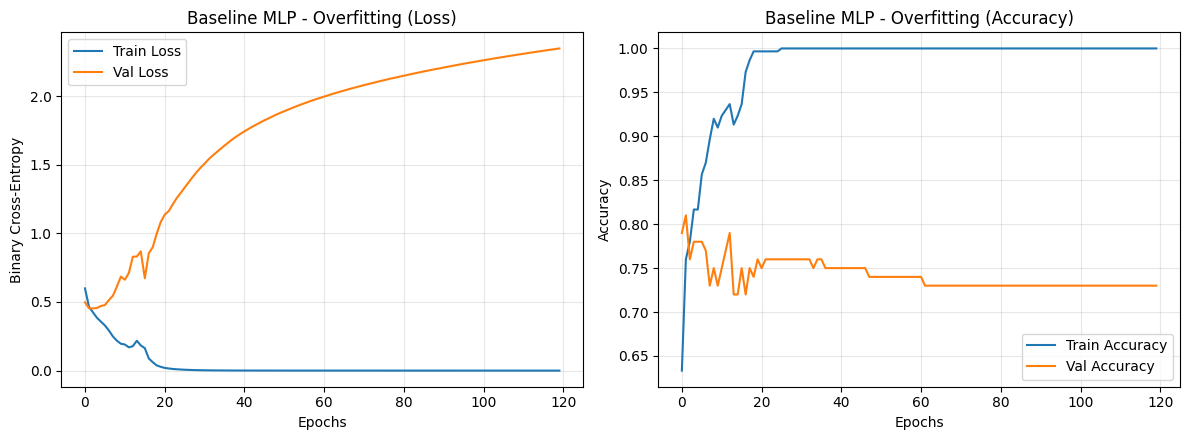

=== Regularization Comparison Table ===
                       Model  Epochs Run  Train Acc  Val Acc  Test Acc  Train-Test Gap
        Baseline (Large MLP)         120     1.0000     0.73      0.81          0.1900
          L2 (lambda=0.0001)         120     1.0000     0.71      0.80          0.2000
           L2 (lambda=0.001)         120     1.0000     0.71      0.80          0.2000
            L2 (lambda=0.01)         120     0.9900     0.71      0.80          0.1900
          Dropout (rate=0.2)         120     1.0000     0.70      0.79          0.2100
          Dropout (rate=0.3)         120     1.0000     0.75      0.76          0.2400
          Dropout (rate=0.5)         120     0.9967     0.77      0.77          0.2267
Early Stopping (patience=10)          13     0.8200     0.77      0.80          0.0200


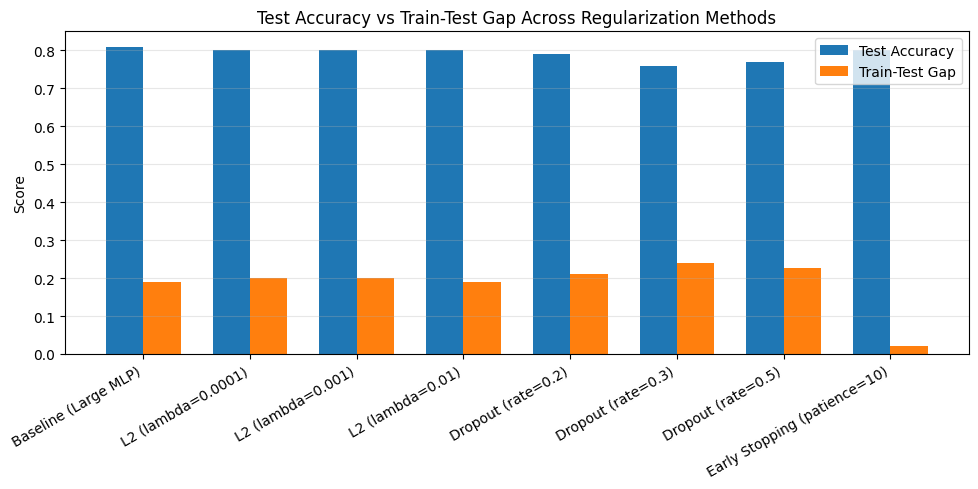

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ==========================================
# Generate Small Tabular Diabetes Dataset (500 records)
# ==========================================
n_samples = 500
glucose = np.random.normal(120, 30, n_samples).clip(50, 220)
bmi = np.random.normal(31, 7, n_samples).clip(18, 55)
age = np.random.randint(21, 75, n_samples)
bp = np.random.normal(72, 12, n_samples).clip(40, 120)
insulin = np.random.normal(100, 50, n_samples).clip(15, 300)
skin_thickness = np.random.normal(25, 10, n_samples).clip(5, 60)
pregnancies = np.random.poisson(3, n_samples)
pedigree = np.random.uniform(0.1, 1.5, n_samples)

# Non-linear clinical risk with noise (encourages overfitting in large models)
logits = (
    0.04 * (glucose - 120)
    + 0.09 * (bmi - 30)
    + 0.03 * (age - 40)
    + 0.8 * (pedigree - 0.6)
    + 0.005 * (insulin - 100)
    + np.random.normal(0, 1.2, n_samples)
)
probs = 1 / (1 + np.exp(-logits))
y = (probs > 0.5).astype(int)

X = np.column_stack([pregnancies, glucose, bp, skin_thickness, insulin, bmi, pedigree, age])

# Split into Train (60%), Val (20%), Test (20%)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=42, stratify=y_train_full
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}\n")

# ==========================================
# Helper: Build Large MLP with Optional Regularization
# ==========================================
def build_large_mlp(input_dim, l2_lambda=0.0, dropout_rate=0.0):
    tf.random.set_seed(42)
    reg = regularizers.l2(l2_lambda) if l2_lambda > 0 else None
    model = keras.Sequential([layers.Input(shape=(input_dim,))])
    for units in [256, 128, 64]:
        model.add(layers.Dense(units, activation="relu", kernel_regularizer=reg))
        if dropout_rate > 0:
            model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.003),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

results = []

def evaluate_and_log(name, model, history):
    _, train_acc = model.evaluate(X_train, y_train, verbose=0)
    _, val_acc = model.evaluate(X_val, y_val, verbose=0)
    _, test_acc = model.evaluate(X_test, y_test, verbose=0)
    gap = train_acc - test_acc
    results.append({
        "Model": name,
        "Epochs Run": len(history.history["loss"]),
        "Train Acc": round(train_acc, 4),
        "Val Acc": round(val_acc, 4),
        "Test Acc": round(test_acc, 4),
        "Train-Test Gap": round(gap, 4)
    })

EPOCHS = 120
BATCH_SIZE = 32

# ==========================================
# Task 1: Deliberately Large Baseline MLP & Overfitting Plot
# ==========================================
baseline = build_large_mlp(X_train.shape[1])
hist_base = baseline.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0
)
evaluate_and_log("Baseline (Large MLP)", baseline, hist_base)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(hist_base.history["loss"], label="Train Loss")
axes[0].plot(hist_base.history["val_loss"], label="Val Loss")
axes[0].set_title("Baseline MLP - Overfitting (Loss)")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Binary Cross-Entropy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(hist_base.history["accuracy"], label="Train Accuracy")
axes[1].plot(hist_base.history["val_accuracy"], label="Val Accuracy")
axes[1].set_title("Baseline MLP - Overfitting (Accuracy)")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# Task 2: Retrain with L2 Regularization (3 lambda values)
# ==========================================
for lam in [1e-4, 1e-3, 1e-2]:
    m_l2 = build_large_mlp(X_train.shape[1], l2_lambda=lam)
    h_l2 = m_l2.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0
    )
    evaluate_and_log(f"L2 (lambda={lam})", m_l2, h_l2)

# ==========================================
# Task 3: Retrain with Dropout (0.2, 0.3, 0.5)
# ==========================================
for rate in [0.2, 0.3, 0.5]:
    m_do = build_large_mlp(X_train.shape[1], dropout_rate=rate)
    h_do = m_do.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0
    )
    evaluate_and_log(f"Dropout (rate={rate})", m_do, h_do)

# ==========================================
# Task 4: Retrain with Early Stopping (Validation Loss)
# ==========================================
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)
m_es = build_large_mlp(X_train.shape[1])
h_es = m_es.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=[early_stop], verbose=0
)
evaluate_and_log("Early Stopping (patience=10)", m_es, h_es)

# ==========================================
# Task 5: Tabulate Test Accuracy & Train-Test Gap
# ==========================================
results_df = pd.DataFrame(results)
print("=== Regularization Comparison Table ===")
print(results_df.to_string(index=False))

# Visual comparison of Test Accuracy vs Train-Test Gap
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(results_df))
width = 0.35
ax.bar(x - width/2, results_df["Test Acc"], width, label="Test Accuracy", color="tab:blue")
ax.bar(x + width/2, results_df["Train-Test Gap"], width, label="Train-Test Gap", color="tab:orange")
ax.set_xticks(x)
ax.set_xticklabels(results_df["Model"], rotation=30, ha="right")
ax.set_ylabel("Score")
ax.set_title("Test Accuracy vs Train-Test Gap Across Regularization Methods")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()